<a href="https://colab.research.google.com/github/SUZUB/ATU/blob/main/ATU_GPU.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
# ==============================================================================
# Cell 1: Infrastructure & Cloud Sync
# ==============================================================================
import os
from google.colab import drive

# 1. Public Git clone / pull
if not os.path.exists('ATU') and not os.path.exists('/content/ATU'):
    !git clone https://github.com/SUZUB/ATU.git
if os.path.exists('/content/ATU'):
    %cd /content/ATU
elif os.path.exists('ATU'):
    %cd ATU
# Force-sync to the latest GitHub version. /content/ATU is a disposable mirror:
# edit code locally and push; any edits made here are discarded (listed first).
!git fetch -q origin && git status --short && git reset -q --hard origin/main
!git log -1 --format="Repo synced to commit %h (%cd): %s" --date=short

# Install project requirements
!pip install -q -r requirements.txt

# yfinance >= 1.8 requires curl_cffi >= 0.17 (yfinance's "chrome" profile resolves to
# chrome152). Upgrade both together; an older curl_cffi still loaded in this runtime
# is what raises ImpersonateError('Impersonating chrome152 is not supported').
!pip install -q -U "yfinance>=1.8.0" "curl_cffi>=0.17.0"

import sys, subprocess, importlib.metadata as md
stale = [
    pkg for pkg in ("curl_cffi", "yfinance")
    if pkg in sys.modules and getattr(sys.modules[pkg], "__version__", None) != md.version(pkg)
]
if stale:
    print(f"Outdated {stale} already loaded in this runtime -> restarting. Re-run from Cell 1 afterwards.")
    os.kill(os.getpid(), 9)  # Colab reconnects automatically with the upgraded packages

# Smoke test in a fresh process, using the same session logic as the pipeline
# (market_data_processor.get_yfinance_session picks a browser profile curl_cffi supports)
probe = subprocess.run(
    [sys.executable, "-c",
     "import yfinance as yf, curl_cffi, market_data_processor as m; "
     "d = m._yf_download(tickers='AAPL', period='5d', interval='5m', progress=False); "
     "print(f'yfinance {yf.__version__} | curl_cffi {curl_cffi.__version__} | "
     "profile {m._YF_SESSION_STATE.get(\"profile\")} | AAPL 5m rows: {len(d)}')"],
    capture_output=True, text=True,
)
print(probe.stdout.strip() or f"yfinance smoke test FAILED:{probe.stderr.strip()[-1500:]}")

# 2. Google Drive Mount
drive.mount('/content/drive')

# 3. Persistent Drive Workspace & Subdirectory Creation
DRIVE_WORKSPACE = '/content/drive/MyDrive/ATU_Workspace'
os.makedirs(DRIVE_WORKSPACE, exist_ok=True)

DATASET_PATH = os.path.join(DRIVE_WORKSPACE, 'datasets')
MODEL_CHECKPOINTS = os.path.join(DRIVE_WORKSPACE, 'checkpoints')
RESULTS_PATH = os.path.join(DRIVE_WORKSPACE, 'results')

os.makedirs(DATASET_PATH, exist_ok=True)
os.makedirs(MODEL_CHECKPOINTS, exist_ok=True)
os.makedirs(RESULTS_PATH, exist_ok=True)

print("\nInfrastructure & Cloud Sync complete.")
print(f"Project Directory: {os.getcwd()}")
print(f"Drive Workspace:   {DRIVE_WORKSPACE}")

/content/ATU
Repo synced to commit de710ae (2026-11-12): feat: trained, persistent ORB model with walk-forward evaluation and leak guard
- Yahoo Finance HTTP session: chrome
yfinance 1.8.0 | curl_cffi 0.17.0 | profile chrome | AAPL 5m rows: 390
Mounted at /content/drive

Infrastructure & Cloud Sync complete.
Project Directory: /content/ATU
Drive Workspace:   /content/drive/MyDrive/ATU_Workspace


In [4]:
# ==============================================================================
# Cell 2: Imports & Setup
# ==============================================================================
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# Ensure ATU root directory is in sys.path
atu_root = Path.cwd()
if str(atu_root) not in sys.path:
    sys.path.insert(0, str(atu_root))

# Drop cached project modules so code pulled in Cell 1 is used without a runtime restart
_project_modules = ("market_data_processor", "sentiment_processor", "constrained_trading_env", "train_and_backtest", "research_strategies", "orb_model")
for _name in [m for m in sys.modules if m in _project_modules or m == "src" or m.startswith("src.")]:
    del sys.modules[_name]

# Undo any yf.download monkey-patch left over from an earlier cell (re-running such a
# patch makes it wrap itself -> RecursionError). The pipeline does not need one.
import yfinance as yf
import yfinance.multi
yf.download = yfinance.multi.download

# Shared pipeline (identical logic to `python train_and_backtest.py`)
from src.train import build_live_state_vector, run_experiment
import research_strategies as rs
import orb_model as om

# Device Auto-detection (FinBERT runs on GPU when available; SB3 MLP agents train on CPU)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Imports & Setup complete.")
print(f"PyTorch Version:  {torch.__version__}")
print(f"Active Device:    {DEVICE.upper()}")
if torch.cuda.is_available():
    print(f"GPU Hardware:     {torch.cuda.get_device_name(0)}")

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Imports & Setup complete.
PyTorch Version:  2.14.1+cu130
Active Device:    CUDA
GPU Hardware:     Tesla T4


In [5]:
# ==============================================================================
# Cell 3: Real Market Data + Real News Sentiment -> final_state_vector
# ==============================================================================
# - Real candles from yfinance. Default: 1-hour bars over ~2 years (~580 training days,
#   ~145 test days). 5-minute bars are limited by Yahoo to the last 60 days (~12 test days,
#   too short to judge a strategy); use INTERVAL = "5m", PERIOD = "60d" for those.
# - Also builds a price-mirrored copy (every return negated) used as extra TRAINING data,
#   so agents cannot profit from a fixed long/short bias.
# - The news step is optional: if it fails, the cell continues with neutral sentiment.
#   Over 2 years the first news fetch takes several minutes; later runs reuse the cache
#   in <workspace>/datasets/news_cache_<TICKER>.csv.
# - FinBERT scores, dated in the exchange timezone, lagged 1 day (Tue news -> Wed candles).
# - Session rules: NSE/BSE (.NS/.BO) 09:15-15:30 IST, square-off 15:15;
#                  US 09:30-16:00 ET, square-off 15:45 (and always at each day's last bar).
TICKER = "AAPL"  # e.g. "RELIANCE.NS"
INTERVAL = "1h"
PERIOD = "730d"
USE_NEWS_SENTIMENT = True  # False = price data only (skips news + FinBERT; sentiment = 0.0)
DRIVE_WORKSPACE = globals().get("DRIVE_WORKSPACE", "/content/drive/MyDrive/ATU_Workspace")

data = build_live_state_vector(
    ticker=TICKER,
    period=PERIOD,
    interval=INTERVAL,
    data_dir=os.path.join(DRIVE_WORKSPACE, "datasets"),
    device=DEVICE,
    use_news=USE_NEWS_SENTIMENT,
)
final_state_vector = data.final_state_vector
print(f"\nEnv Rules: {data.env_kwargs}")
display(final_state_vector.head(3))



[Data 1/3] Downloading real 1h candles for AAPL (period=730d)...
  - Yahoo Finance HTTP session: chrome
  - 5,044 candles | 2023-12-21 -> 2026-11-12 | 726 sessions | ~7 bars/day | tz=America/New_York

[Data 2/3] Collecting real headlines for AAPL...


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


  - News fetch: 2,609 unique headlines over 717 days (2 RSS requests, 0 failed; queries=['Apple stock', 'AAPL stock'])


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

... (7 outputs left out)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


  - Daily sentiment: 717 days | mean +0.000

[Data 3/3] Merging into final_state_vector (sentiment lagged 1 day, expires after 4)...
  - Shape: (5044, 25)
  - Non-zero sentiment: 98.8% of all bars, 100.0% of test bars

Env Rules: {'session_start_time': datetime.time(9, 30), 'session_end_time': datetime.time(16, 0), 'auto_square_off_time': datetime.time(15, 45), 'min_hold_bars': 1, 'reentry_cooldown_bars': 1}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Open,High,Low,Close,Volume,RSI,MACD,MACD_Signal,MACD_Diff,ATR,...,raw_high,raw_low,raw_open,gap_pct,first_bar_ret_pct,rel_volume,vwap_dist_pct,or_pos,day_ret_pct,daily_sentiment
Date,,,,,,,,,,,,,,,,,,,,,
2023-12-21 14:30:00-05:00,0.240952,0.237019,0.243638,0.244293,0.072762,0.344569,0.583134,0.617416,0.362665,0.027878,...,194.419998,193.759995,193.994995,0.646689,0.148688,0.00000,-0.155604,-0.683585,-0.864304,0.015354
2023-12-21 15:30:00-05:00,0.244327,0.241555,0.248334,0.246528,0.082636,0.381136,0.584453,0.614123,0.373913,0.025419,...,194.979996,194.332108,194.410004,0.646689,0.148688,0.00000,-0.011400,-0.561954,-0.724127,0.015354
2023-12-22 09:30:00-05:00,0.250590,0.245039,0.249097,0.246406,0.126694,0.379890,0.585917,0.611826,0.383225,0.027192,...,195.410004,194.425003,195.179993,0.256832,-0.007705,-0.63665,-0.086402,-0.256355,-0.263859,-0.935665



Train: 4,035 candles (582 days) | Test: 1,009 candles (145 days)
Training budget per agent: 5 x 32,280 = 161,400 steps (~20.0 passes; mirror on; resume off)

#################################################################
#  SEED 0
#################################################################

Building PPO training environment (seed 0)...
[Fresh Initialization] PPO (resume=False).
Using cpu device
[Training] PPO: 5 chunks x 32,280 steps = 161,400 timesteps


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Logging to /content/drive/MyDrive/ATU_Workspace/training_logs/seed_0/ppo/PPO_0
  PPO chunk 1/5 done (32,768 total timesteps) -> saved
Logging to /content/drive/MyDrive/ATU_Workspace/training_logs/seed_0/ppo/PPO_0
  PPO chunk 2/5 done (65,536 total timesteps) -> saved
Logging to /content/drive/MyDrive/ATU_Workspace/training_logs/seed_0/ppo/PPO_0
  PPO chunk 3/5 done (98,304 total timesteps) -> saved
Logging to /content/drive/MyDrive/ATU_Workspace/training_logs/seed_0/ppo/PPO_0
  PPO chunk 4/5 done (131,072 total timesteps) -> saved
Logging to /content/drive/MyDrive/ATU_Workspace/training_logs/seed_0/ppo/PPO_0
  PPO chunk 5/5 done (163,840 total timesteps) -> saved

Building A2C training environment (seed 0)...
[Fresh Initialization] A2C (resume=False).
Using cpu device
[Training] A2C: 5 chunks x 32,280 steps = 161,400 timesteps
Logging to /content/drive/MyDrive/ATU_Workspace/training_logs/seed_0/a2c/A2C_0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


------------------------------------
| time/                 |          |
|    fps                | 940      |
|    iterations         | 1000     |
|    time_elapsed       | 10       |
|    total_timesteps    | 10000    |
| train/                |          |
|    entropy_loss       | -0.017   |
|    explained_variance | 0.64     |
|    learning_rate      | 0.0007   |
|    n_updates          | 999      |
|    policy_loss        | 1.07e-05 |
|    value_loss         | 0.000738 |
------------------------------------
------------------------------------
| time/                 |          |
|    fps                | 944      |
|    iterations         | 2000     |
|    time_elapsed       | 21       |
|    total_timesteps    | 20000    |
| train/                |          |
|    entropy_loss       | -0.685   |
|    explained_variance | -0.297   |
|    learning_rate      | 0.0007   |
|    n_updates          | 1999     |
|    policy_loss        | -0.542   |
|    value_loss         | 0.61     |
-

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (15 outputs left out)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Backtest completed: 1,008 steps, 1 closed trades, 1 stop-loss exits.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



      ENSEMBLE (PPO + A2C) INSTITUTIONAL PERFORMANCE REPORT    
 Ticker / Test Window:     AAPL | 2026-04-20 -> 2026-11-12
 Initial Balance:          $100,000.00
 Final Compounded Balance: $99,999.91
 Net Profit (After Fees):  $-0.09 (-0.00%)
 Gross Profit (Pre-Fees):  $+14.91 (+0.01%)
 Total Fees & Charges:     $15.00
 Closed Trades:            1 (Win Rate: 0.0%, Stop-Loss Exits: 1)
 Exits: Trail / TP / Cap:  0 / 0 / 0   Avg Win / Loss Trade: $+0.00 / $-0.09
 Maximum Drawdown:         -0.43%
 Sharpe Ratio (Ann.):      0.0027
 Sortino Ratio (Ann.):     0.0040
 Profit Factor (Trades):   0.00
 Buy & Hold (same window): +29.95%  (strategy minus B&H: -29.95%)
-----------------------------------------------------------------
 Trading Days:             145 (green 0 | red 1 | flat 144)
 Green-Day Rate:           0.0% of days with a trade
 Avg Green / Red Day:      $+0.00 / $-0.09
 Best / Worst Day:         $+0.00 / $-0.09
 Sub-Windows Profitable:   0/4  [+0.00%, -0.00%, +0.00%, +0.00%]
-----

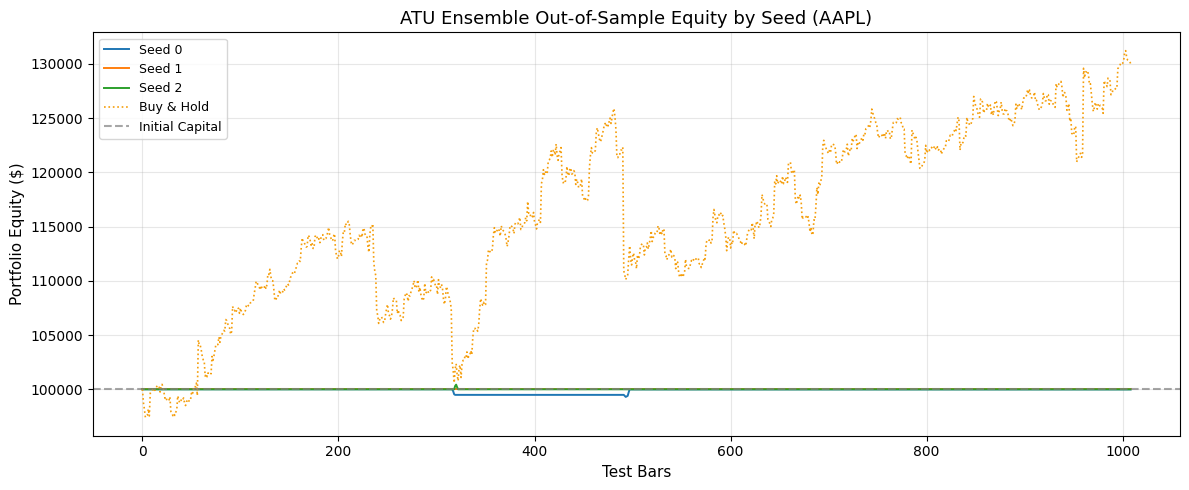


----- Seed 0 -----
      ENSEMBLE (PPO + A2C) INSTITUTIONAL PERFORMANCE REPORT    
 Ticker / Test Window:     AAPL | 2026-04-20 -> 2026-11-12
 Initial Balance:          $100,000.00
 Final Compounded Balance: $99,986.82
 Net Profit (After Fees):  $-13.18 (-0.01%)
 Gross Profit (Pre-Fees):  $+16.75 (+0.02%)
 Total Fees & Charges:     $29.93
 Closed Trades:            2 (Win Rate: 50.0%, Stop-Loss Exits: 1)
 Exits: Trail / TP / Cap:  0 / 0 / 0   Avg Win / Loss Trade: $+501.67 / $-514.85
 Maximum Drawdown:         -0.70%
 Sharpe Ratio (Ann.):      -0.0272
 Sortino Ratio (Ann.):     -0.0423
 Profit Factor (Trades):   0.97
 Buy & Hold (same window): +29.95%  (strategy minus B&H: -29.96%)
-----------------------------------------------------------------
 Trading Days:             145 (green 1 | red 2 | flat 142)
 Green-Day Rate:           33.3% of days with a trade
 Avg Green / Red Day:      $+509.29 / $-261.23
 Best / Worst Day:         $+509.29 / $-514.85
 Sub-Windows Profitable:   0/4  [+

In [6]:
# ==============================================================================
# Cell 4: Multi-Seed Ensemble RL (PPO + A2C) & Backtest
# ==============================================================================
# - One PPO + A2C ensemble per seed, trained on the same 80% (+ its price mirror) and
#   tested on the same 20%. A real edge shows up in most seeds; one good seed is luck.
# - Training budget = TRAIN_PASSES passes over the training data (fixed, small: more
#   passes over the same history = memorization). Fresh models every run (RESUME = False)
#   so each run is a clean, comparable experiment.
# - Rewards are VecNormalize'd for training only; the backtest runs on a raw env.
# - Per-seed reports, daily P&L and plots: <Drive>/results/seed_<n>/
#   Cross-seed summary: <Drive>/results/seed_summary.txt and equity_by_seed.png
SEEDS = [0, 1, 2]
TRAIN_PASSES = 20
RESUME = False

assert "data" in globals(), "Run Cell 3 first."
experiment = run_experiment(
    data,
    workspace=DRIVE_WORKSPACE,
    seeds=SEEDS,
    train_passes=TRAIN_PASSES,
    resume=RESUME,
    show_plot=True,
)
for seed, run in experiment.runs.items():
    print(f"\n----- Seed {seed} -----\n" + run.report)
print("\n" + experiment.report)


  AAPL       4680 bars  2026-08-20 -> 2026-11-12  (60 sessions)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


  MSFT       4680 bars  2026-08-20 -> 2026-11-12  (60 sessions)
  NVDA       4680 bars  2026-08-20 -> 2026-11-12  (60 sessions)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


  AMZN       4680 bars  2026-08-20 -> 2026-11-12  (60 sessions)
  GOOGL      4680 bars  2026-08-20 -> 2026-11-12  (60 sessions)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (8 outputs left out)

  QQQ        4680 bars  2026-08-20 -> 2026-11-12  (60 sessions)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


 OPENING RANGE BREAKOUT  ORB 1:3
 13 tickers | 60 sessions 2026-08-20 -> 2026-11-12
 Risk 1.0% of allocated capital per trade, leverage cap 4x, fees 0.010% per side
 Net return:        +0.82%   (gross +3.13%, equal-weight buy & hold +0.71%)
 Trades:            777  win rate 35.5%  avg +0.02R  profit factor 1.02
 Exits:             target 119 | stop 436 | close 222
 Days:              green 31 / red 29 -> green-day rate 51.7%
 Max drawdown:      -4.04%   Sharpe (daily, ann.) 0.42
------------------------------------------------------------------------
 Consistency (net return):
   first half   2026-08-20 -> 2026-10-01: -2.58%  green days 53%  sharpe -3.47
   second half  2026-10-02 -> 2026-11-12: +3.49%  green days 50%  sharpe 2.60
 Fee sensitivity (net return):
   0.003%/side +2.50% | 0.010%/side +0.82% | 0.020%/side -1.53% | 0.030%/side -3.83%
 Per ticker (net return):
   AAPL -12.4%, JPM -12.1%, AVGO -11.3%, NVDA -7.5%, GOOGL +0.0%, QQQ +0.7%, SPY +3.9%, TSLA +4.4%, AMD +4.8%, NFLX +

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


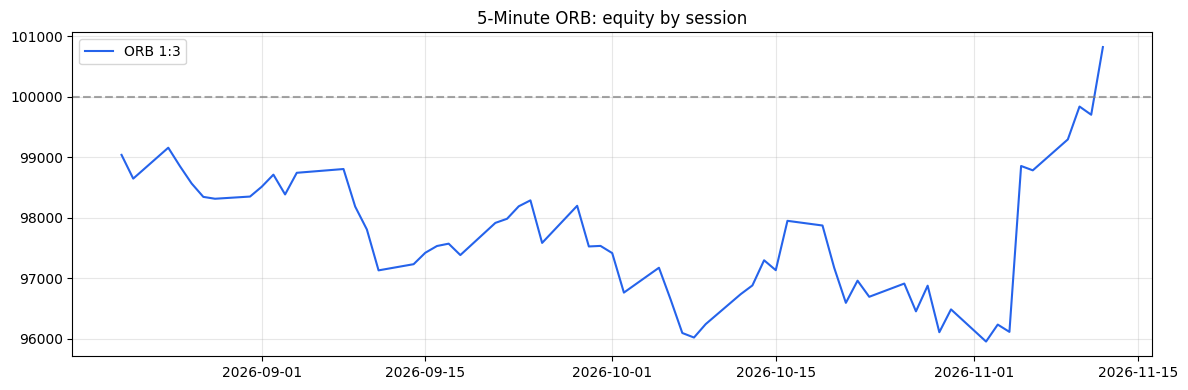

In [7]:
# ==============================================================================
# Cell 5: Research Strategy - 5-Minute Opening Range Breakout (rule-based, no RL)
# ==============================================================================
# Zarattini & Aziz (2023), SSRN 4416622, and Zarattini, Barbon & Aziz (2024), SFI 24-98:
# - First 5-minute candle = opening range. Green -> long at the next bar's open,
#   red -> short, doji -> no trade. Stop = other side of the opening range.
# - Exit at RR x risk (RR = 3 -> 1:3 risk:reward) or at the session close.
# - Each trade risks RISK_PER_TRADE of its share of capital (leverage capped).
# Yahoo keeps 5-minute bars for only 60 days, so every run MERGES new bars into
# <Drive>/datasets/intraday/: the test history grows each time you run this cell.
# Judge it by the consistency lines: both halves positive at YOUR real fee level.
RESEARCH_TICKERS = rs.DEFAULT_UNIVERSE  # or e.g. ["RELIANCE.NS", "TCS.NS", "INFY.NS", "HDFCBANK.NS"]
RR = 3.0                 # 1:3 risk:reward; None = hold to the close
RISK_PER_TRADE = 0.01    # 1% of allocated capital per trade (paper setting)
MAX_LEVERAGE = 4.0       # paper setting; use 1.0 for no leverage
FEE_PER_SIDE = 0.0001    # 0.01% fees + slippage per side; NSE intraday is closer to 0.02-0.03%

intraday = rs.download_universe(
    RESEARCH_TICKERS, period="60d", interval="5m",
    cache_dir=os.path.join(DRIVE_WORKSPACE, "datasets", "intraday"),
)
report_text, orb = rs.research_report(
    intraday, rr=RR, risk_per_trade=RISK_PER_TRADE, max_leverage=MAX_LEVERAGE, fee_rate=FEE_PER_SIDE,
)
research_dir = os.path.join(DRIVE_WORKSPACE, "results", "research")
os.makedirs(research_dir, exist_ok=True)
orb.trades.to_csv(os.path.join(research_dir, "orb_trades.csv"), index=False)
orb.daily.to_csv(os.path.join(research_dir, "orb_daily.csv"))
with open(os.path.join(research_dir, "orb_report.txt"), "w", encoding="utf-8") as f:
    f.write(report_text)
print(report_text)

plt.figure(figsize=(12, 4))
plt.plot(pd.to_datetime(orb.daily.index), orb.daily["equity"], color="#2563EB", label=orb.name)
plt.axhline(orb.initial_capital, color="gray", linestyle="--", alpha=0.7)
plt.title("5-Minute ORB: equity by session")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


Loaded saved model: trained 2026-11-12T18:40:14 on 59 sessions (2360 samples).


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

5-minute history: 40 tickers, 60 sessions


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Live signal source: PLAIN ORB (model has not beaten it in both halves yet)
 ORB MODEL - walk-forward, OUT-OF-SAMPLE only (retrained every 5 sessions on the past)
 Test sessions: 2026-09-18 -> 2026-11-12 (40) | fees 0.010%/side | RR 1:3 | min edge +0.10R
 Strategy           Net  Trades    Win   Avg R  Green days        MaxDD  Sharpe
 Model            +1.59%    750   34.9%  -0.01R   20/40  ( 50%)   -3.03%   1.39
 Plain ORB        +3.01%   1598   38.0%  +0.08R   22/40  ( 55%)   -0.86%   4.01
------------------------------------------------------------------------------
 First half  (2026-09-18 -> 2026-10-15):  model -0.55% | plain ORB +1.72%
 Second half (2026-10-16 -> 2026-11-12): model +2.16% | plain ORB +1.27%
 The model is only useful if it beats plain ORB in BOTH halves, and keeps doing so
 as more 5-minute history accumulates.
Saved model -> /content/drive/MyDrive/ATU_Workspace/models/orb_model.joblib  (2400 samples, 60 sessions, +1 sessions vs. previous model)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



Signals for 2026-11-12 (stop = other side of the first 5-min candle, target = 1:3):


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,ticker,session,source,signal,pred_r,ref_price,stop,target
0,MSFT,2026-11-12,plain ORB,LONG,1.320960,522.469971,520.510010,528.349854
1,AMZN,2026-11-12,plain ORB,LONG,1.266409,269.000000,267.834991,272.495026
2,GOOGL,2026-11-12,plain ORB,LONG,0.999467,295.070007,293.799988,298.880066
3,SMCI,2026-11-12,plain ORB,LONG,0.930922,27.580000,26.961000,29.436998
4,AVGO,2026-11-12,plain ORB,LONG,0.910290,361.600006,354.720001,382.240021
5,MU,2026-11-12,plain ORB,LONG,0.894527,785.003296,767.500000,837.513184
6,NVDA,2026-11-12,plain ORB,LONG,0.890399,156.257996,149.270004,177.221970
7,TSLA,2026-11-12,plain ORB,LONG,0.863730,392.119995,385.200012,412.879944
8,ORCL,2026-11-12,plain ORB,LONG,0.855740,124.860001,123.050102,130.289696
9,DIS,2026-11-12,plain ORB,LONG,0.839383,119.635002,119.430000,120.250008


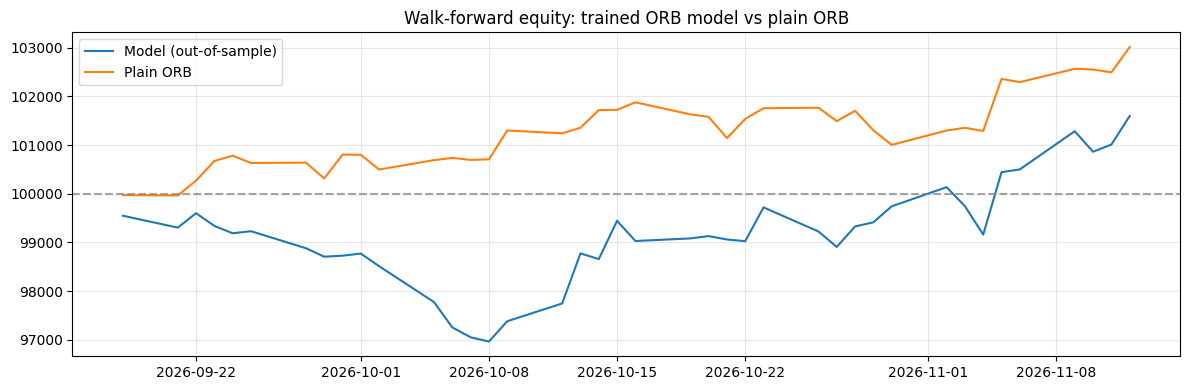

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [8]:
# ==============================================================================
# Cell 6: Trained ORB Model - load, update with new data, save, today's signals
# ==============================================================================
# Learns from every (stock, day) which opening-range trades are worth taking:
# features at 09:35 (first 5-min candle, gap, relative volume, previous day, market)
# -> expected net R of a 1:3 bracket LONG and SHORT (gradient-boosted trees).
# Every run: loads the saved model, merges new 5-min bars into Drive (history grows),
# re-checks the features for look-ahead leaks, evaluates walk-forward OUT-OF-SAMPLE
# against plain ORB, retrains on ALL history and saves:
#   <Drive>/models/orb_model.joblib (latest) + a dated copy per run + orb_model.json
# Live signals use the model only if it beat plain ORB in both test halves;
# otherwise they fall back to plain ORB. Run after 09:35 ET for today's signals.
ORB_FEE_PER_SIDE = 0.0001   # your real fees + slippage per side
ORB_MIN_EDGE = 0.10          # trade only when the predicted net gain is above +0.10R

orb_run = om.train_and_save(
    DRIVE_WORKSPACE,
    tickers=om.MODEL_UNIVERSE,
    fee_rate=ORB_FEE_PER_SIDE,
    min_edge=ORB_MIN_EDGE,
)
signals = om.todays_signals(orb_run["model"], orb_run["data"])
print(f"\nSignals for {signals['session'].iloc[0] if len(signals) else 'n/a'} "
      f"(stop = other side of the first 5-min candle, target = 1:3):")
display(signals[signals["signal"] != "SKIP"])

ev = orb_run["evaluation"]
if "model_daily" in ev:
    plt.figure(figsize=(12, 4))
    plt.plot(pd.to_datetime(ev["model_daily"].index), ev["model_daily"]["equity"], label="Model (out-of-sample)")
    plt.plot(pd.to_datetime(ev["baseline_daily"].index), ev["baseline_daily"]["equity"], label="Plain ORB")
    plt.axhline(100_000, color="gray", linestyle="--", alpha=0.7)
    plt.title("Walk-forward equity: trained ORB model vs plain ORB")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()
